# Unsupervised Learning 

In this lab we will try to obtain valuable information using Unsupervised Learning techniques.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Loading and Inspection of the data

In [2]:
path_csv = "https://raw.githubusercontent.com/LorenzoTonet/Intro_to_ML_26-27/refs/heads/main/data/Dry_Bean_Dataset.csv"
df = pd.read_csv(path_csv)
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


Let's do some pre-processing of the data:
- separate numerical features
- encode the true labels
- since scales are really different, standardize them

In [4]:
# Let's separate the features from the labels
X_numerical = df.drop('Class', axis=1)
labels = df['Class'].values
X_train = X_numerical.values

# Encode the labels as integers
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(labels)


## Principal Component Analysis (PCA)

**Objective**: find the set of orthogonal directions along which the variance of the data is the highest.

Summary of the method:

* Center the data feature matrix $X$ by computing $X_{\text{centered}} = X - \mu_X$ (or in this case $X_{\text{standardized}} = \frac{X - \mu_X}{\sigma_X}$);

* Compute the covariance matrix $C$ of the data as $C=\frac{1}{N-1} X^T X$;

* Compute eigenvalues and eigenvectors of the covariance matrix $C$ (using the function `eigh` of the `scipy.LA` module), and sort them according to the decreasing order of the eigenvalues. Arrange them as column of a matrix $A$.

**Recall**: eigenvalues give information about the variance of the data along the direction of the corresponding eigenvector.


## Centering vs Standardizing in PCA

**Centering** (subtract the mean) is **always required**. PCA diagonalizes the covariance matrix, and without centering the first component is pulled toward the data mean instead of the direction of maximum variance.

$$
X_c = X - \mathbf{1}\bar{x}^\top
$$

**Standardizing** (also divide by the standard deviation) is an **optional** extra step that changes the problem: PCA is then performed on the correlation matrix instead of the covariance matrix.

$$
X_s = X_c \, \mathrm{diag}(\sigma_1, \dots, \sigma_d)^{-1}
$$


In [5]:
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_raw = X_train.copy()
X_train = (X_train - X_mean) / X_std

In [6]:
class MyPCA:
    """PCA via eigendecomposition of the covariance matrix."""
    #TODO: Implement the PCA algorithm
    def __init__(self):
        self.mean_ = None
        self.scale_ = None
        self.components_ = None
        self.eigenvalues_ = None
        self.explained_variance_ratio_ = None


    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = None
        Xc = X - self.mean_
            
        C = Xc.T @ Xc / (X.shape[0] - 1)           # covariance matrix (unbiased)
        eigval, eigvec = np.linalg.eigh(C)         # eigh: symmetric matrix, ascending eigenvalues
        order = np.argsort(eigval)[::-1]           # sort by decreasing eigenvalue
        self.eigenvalues_ = eigval[order]
        self.components_ = eigvec[:, order]        # columns = principal directions
        self.explained_variance_ratio_ = self.eigenvalues_ / self.eigenvalues_.sum()
        return self

    def transform(self, X, k=None):
        Z = (X - self.mean_) @ self.components_
        return Z if k is None else Z[:, :k]

    def inverse_transform(self, Z):
        k = Z.shape[1]
        return Z @ self.components_[:, :k].T + self.mean_

pca = MyPCA().fit(X_train)

In [7]:
cumulative_var = np.cumsum(pca.explained_variance_ratio_)
threshold = 0.95

k = np.argmax(cumulative_var >= threshold) + 1

print(f"Components needed for {threshold:.0%} variance: {k}")

Components needed for 95% variance: 4


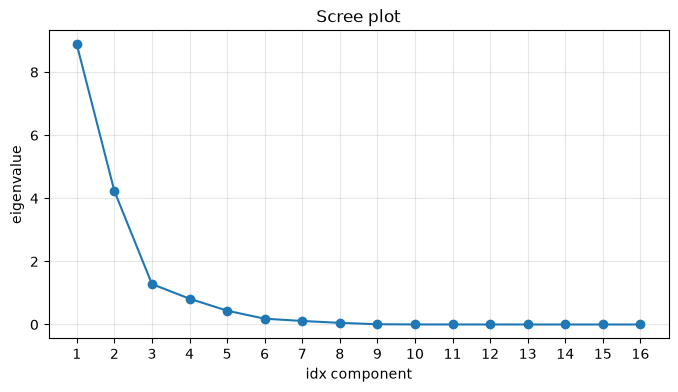

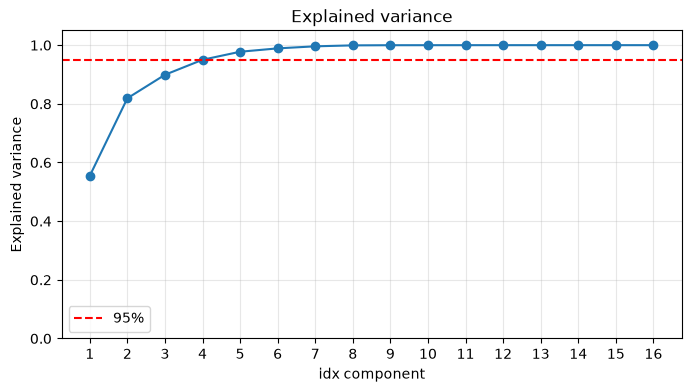

In [8]:
eigenvalues = pca.eigenvalues_
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

components = np.arange(1, len(eigenvalues) + 1)

plt.figure(figsize=(8, 4))
plt.plot(components, eigenvalues, marker="o")
plt.xlabel("idx component")
plt.ylabel("eigenvalue")
plt.title("Scree plot")
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(components, cumulative_var, marker="o")
plt.axhline(y=threshold, linestyle="--", color="red", label="95%")
plt.xlabel("idx component")
plt.ylabel("Explained variance")
plt.title("Explained variance")
plt.ylim(0, 1.05)
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

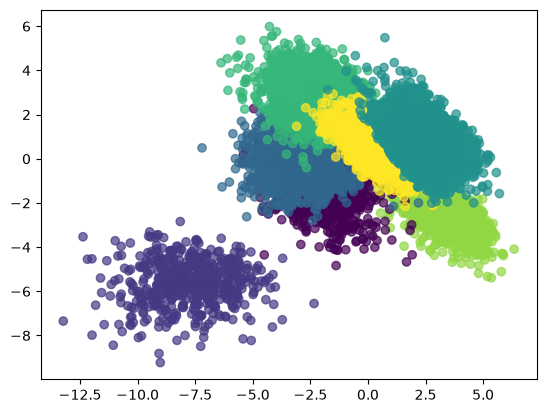

In [9]:
new_X = pca.transform(X_train, k=3)
plt.scatter(new_X[:, 0], new_X[:, 1], c=y, cmap='viridis', alpha=0.7)

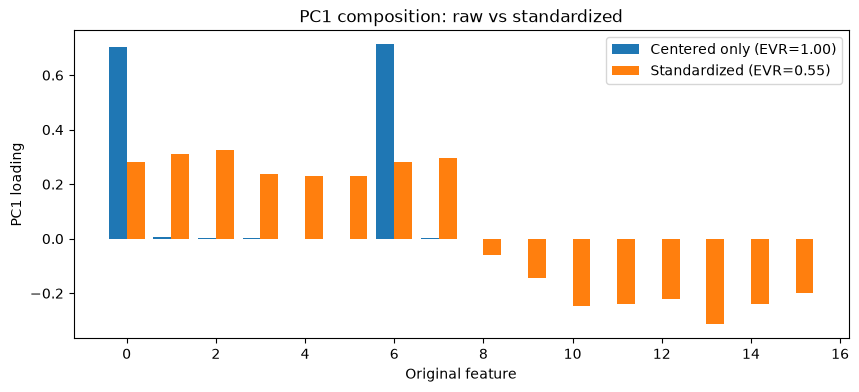

In [10]:
pca_raw = MyPCA().fit(X_raw)   # centered only (covariance PCA)
pca_std = MyPCA().fit(X_train)     # centered + standardized (correlation PCA)

def pc1(pca):
    v = pca.components_[:, 0]
    return v * np.sign(v[np.argmax(np.abs(v))])   # eigenvector sign is arbitrary: fix it for comparison

d = X_train.shape[1]
idx = np.arange(d)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(idx - 0.2, pc1(pca_raw), width=0.4, label=f"Centered only (EVR={pca_raw.explained_variance_ratio_[0]:.2f})")
ax.bar(idx + 0.2, pc1(pca_std), width=0.4, label=f"Standardized (EVR={pca_std.explained_variance_ratio_[0]:.2f})")
ax.set_xlabel("Original feature")
ax.set_ylabel("PC1 loading")
ax.set_title("PC1 composition: raw vs standardized")
ax.legend()
plt.show()

---

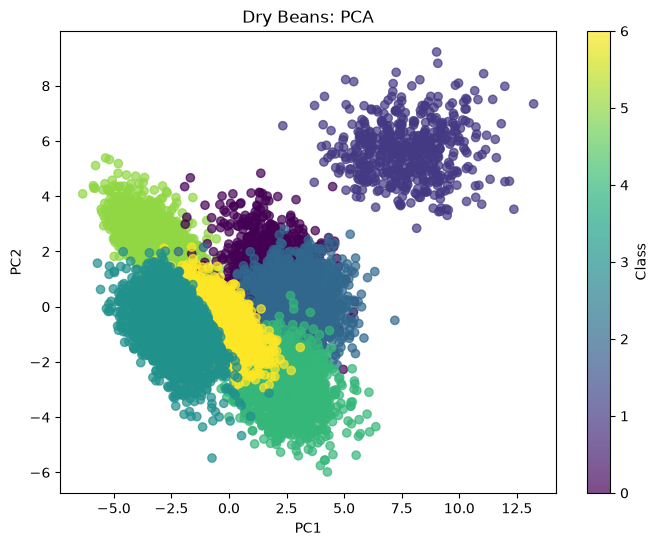

In [11]:
from sklearn.decomposition import PCA

# Fit
pca = PCA()
X_pca = pca.fit_transform(X_train)

# Projection
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Dry Beans: PCA")
plt.colorbar(scatter, label="Class")
plt.show()

---

## The first clustering algorithm: K-means

We will compute the k-means clustering using two types of initialization:
    
  1. Random initialization: cluster centroids are initialized picking random points from the dataset;
  
  2. k-means++: choose first cluster center at random, then choose new cluster centers in such a way that they are far from existing centers.

# K-Means(X, K)

**Input:** dataset $X = \{x_1, \dots, x_N\} \subset \mathbb{R}^d$, number of clusters $K$ 

**Output:** centroids $\{\mu_1, \dots, \mu_K\}$ and cluster assignments $\{c_1, \dots, c_N\}$

1. **Initialize** $K$ centroids $\mu_1, \dots, \mu_K$ randomly (e.g., by sampling $K$ distinct points from $X$).

2. **Repeat until convergence** (assignments no longer change, or the centroids move less than a tolerance $\varepsilon$):

   a. **Assignment step:** assign each point to its nearest centroid.

      $$
      c_i = \underset{k \in \{1, \dots, K\}}{\arg\min} \; \|x_i - \mu_k\|_2^2, \qquad i = 1, \dots, N
      $$

   b. **Update step:** recompute each centroid as the mean of the points assigned to its cluster.

      $$
      \mu_k = \frac{1}{N_k} \sum_{i=1}^{N} \mathbb{1}[c_i = k] \, x_i, \qquad N_k = \sum_{i=1}^{N} \mathbb{1}[c_i = k]
      $$

3. **Return** the assignments $\{c_i\}$ and the centroids $\{\mu_k\}$.

In [12]:
def my_kmeans(X, k, max_iters=100, tol=1e-4):
    #TODO: Implement the K-means clustering algorithm
    """K-means clustering algorithm."""
    n_samples, n_features = X.shape

    labels = np.zeros(n_samples, dtype=int)
    # Randomly initialize centroids
    centroids_idx = np.random.choice(n_samples, size=k, replace=False)
    centroids = X[centroids_idx]
    new_centroids = np.zeros((k, n_features))
    
    for _ in range(max_iters):
        # Assign clusters based on closest centroid
        # Create a distance matrix to store distances from each sample to each centroid -> N x k
        distances = np.full((n_samples, k), np.inf)

        for i in range(k):
            for j in range(n_samples):
                distances[j, i] = np.linalg.norm(X[j] - centroids[i])

        # Assign labels based on the closest centroid
        for j in range(n_samples):
            labels[j] = np.argmin(distances[j, :])
        
        # Update centroids
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                new_centroids[i] = cluster_points.mean(axis=0)
            else:
                # If a cluster has no points assigned, reinitialize its centroid randomly
                new_centroids[i] = X[np.random.choice(n_samples)]
        
        # Check for convergence (if centroids do not change)
        if np.all(np.abs(centroids - new_centroids) < tol):
            break
        
        centroids = new_centroids
    
    return labels, centroids

In [13]:
labels, centroids = my_kmeans(new_X, k=6)

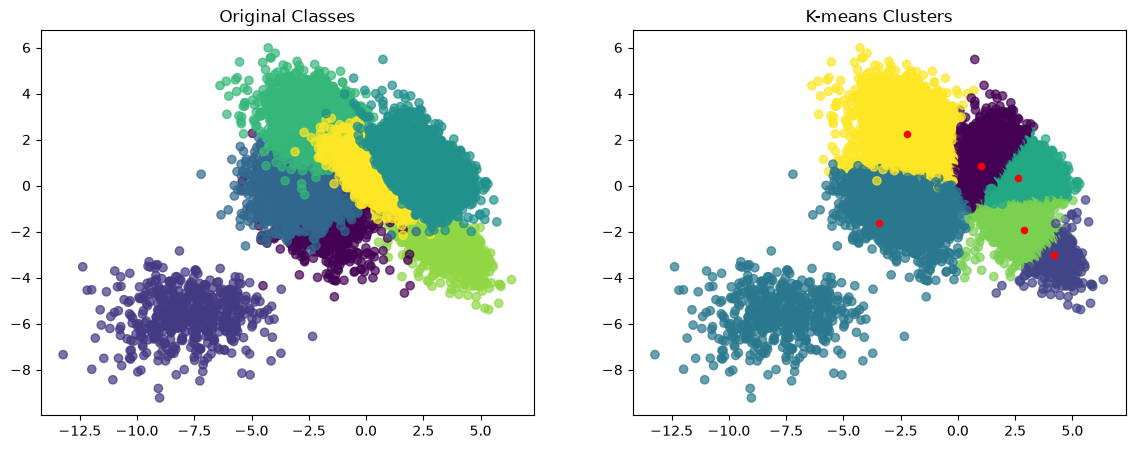

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(new_X[:, 0], new_X[:, 1], c=y, cmap='viridis', alpha=0.7)
ax[0].set_title("Original Classes")

ax[1].scatter(new_X[:, 0], new_X[:, 1], c=labels, cmap='viridis', alpha=0.7)
ax[1].set_title("K-means Clusters")
ax[1].scatter(centroids[:, 0], centroids[:, 1], c='red', marker='o', s=20, label='Centroids')

### K-means and Its Variants

- **K-means++:** Improves centroid initialization by choosing initial centroids that are more likely to be far apart. This often leads to better clustering results and faster convergence.

- **K-medoids:** Similar to K-means, but each cluster center (the *medoid*) is an actual data point, chosen to minimize the sum of distances to other points in the cluster. It is more robust to outliers and can use different distance metrics.

- **Mini-batch K-means:** Updates centroids using small random subsets of the data instead of the entire dataset at each iteration. It is faster and more scalable for large datasets.

- **Bisecting K-means:** Starts with all points in one cluster and repeatedly splits a cluster into two using K-means until the desired number of clusters is reached.

**Key difference:** K-means minimizes the within-cluster sum of squared Euclidean distances, while its variants modify initialization, the choice of cluster representative, or the optimization strategy.

---

# Let's play with other algorithms

In [15]:
# Carica MNIST
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

idx = np.random.choice(len(X), 5000, replace=False)
X_sub = X[idx].astype(np.float32) / 255.0
y_sub = y[idx]

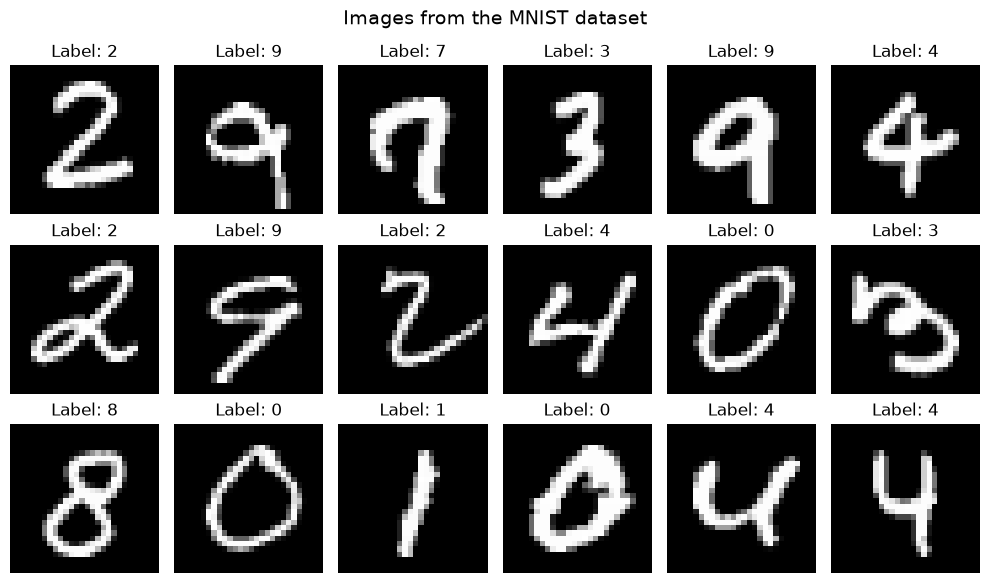

In [16]:
fig, axes = plt.subplots(3, 6, figsize=(10, 6))
indices = np.random.choice(len(X), size=18, replace=False)

for ax, idx in zip(axes.ravel(), indices):
    image = X[idx].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")

plt.suptitle("Images from the MNIST dataset", fontsize=14)
plt.tight_layout()
plt.show()

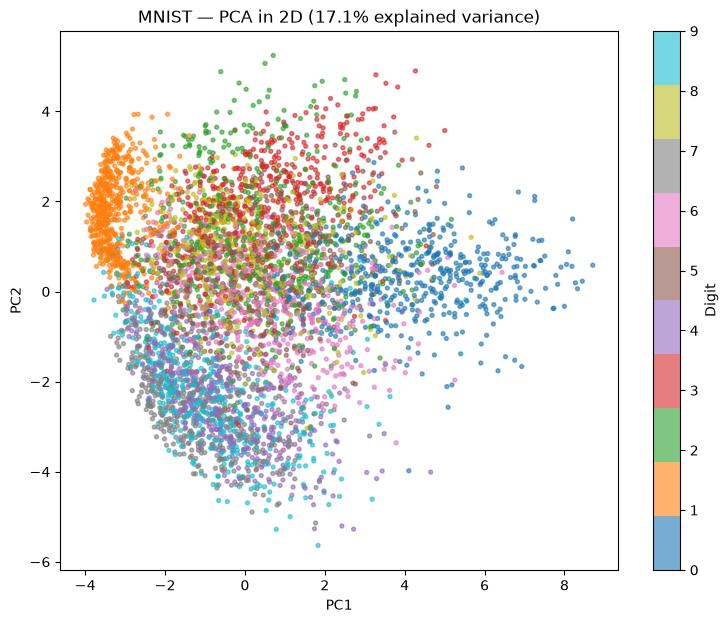

In [17]:
from sklearn.decomposition import PCA
# PCA in 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sub)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_sub, cmap="tab10", s=8, alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(
    "MNIST — PCA in 2D "
    f"({pca.explained_variance_ratio_.sum():.1%} explained variance)"
)
plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.show()

# Isomap (Isometric Feature Mapping)
### by Tenenbaum et al (2000)

Isomap is a **nonlinear** dimensionality reduction method. The idea: data often lie on a low-dimensional **manifold** curved in a high-dimensional space, so straight-line (Euclidean) distances are misleading. Isomap replaces them with **geodesic distances**, i.e. distances measured along the manifold, and then finds an embedding that preserves them.

## Idea

1. **Neighborhood graph.** Connect each point $x_i$ to its $k$ nearest neighbors (or to all points within a radius $\varepsilon$), weighting each edge by the Euclidean distance $\|x_i - x_j\|$.

2. **Geodesic distances.** Approximate the distance along the manifold by the **shortest path** in the graph between every pair of points (Dijkstra or Floyd-Warshall):

   $$
   D^{G}_{ij} = \text{length of the shortest path from } x_i \text{ to } x_j
   $$

3. **Embedding via classical MDS.** Find $y_i \in \mathbb{R}^m$ whose Euclidean distances match $D^G$. Double-center the squared distance matrix,

   $$
   B = -\frac{1}{2} H \, (D^{G})^{\circ 2} \, H, \qquad H = I - \frac{1}{N}\mathbf{1}\mathbf{1}^\top
   $$

   and take the top $m$ eigenvectors $v_l$ and eigenvalues $\lambda_l$ of $B$:

   $$
   Y = \left[\sqrt{\lambda_1}\, v_1, \dots, \sqrt{\lambda_m}\, v_m\right]
   $$

   This minimizes $\sum_{i,j} \left(D^G_{ij} - \|y_i - y_j\|\right)^2$ in the sense of classical MDS.

## Isomap vs PCA

Isomap is essentially **PCA/MDS applied to geodesic distances** instead of Euclidean ones. If the data lie on a flat (linear) subspace, geodesic and Euclidean distances coincide and Isomap reduces to PCA.

## Caveats

- Sensitive to the choice of $k$ (or $\varepsilon$): too large creates "short-circuit" edges across the manifold, too small disconnects the graph.
- Sensitive to noise, and assumes the manifold is **convex** and isometric to a flat region of $\mathbb{R}^m$.
- Unlike t-SNE, it preserves **global** structure, but it is deterministic and the eigendecomposition costs $O(N^3)$.

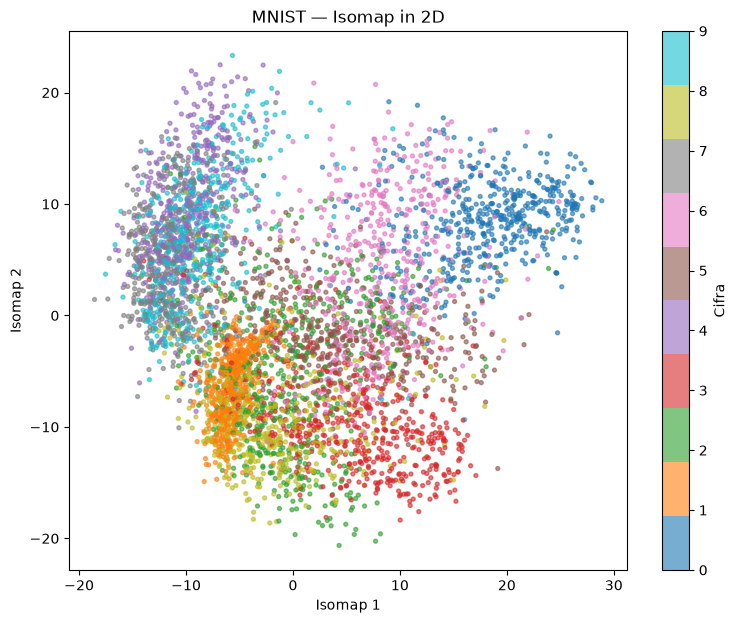

In [18]:
from sklearn.manifold import Isomap

# Isomap in 2D
isomap = Isomap(n_components=2, n_neighbors=10)

X_isomap = isomap.fit_transform(X_sub)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    X_isomap[:, 0],
    X_isomap[:, 1],
    c=y_sub,
    cmap="tab10",
    s=8,
    alpha=0.6
)

plt.xlabel("Isomap 1")
plt.ylabel("Isomap 2")
plt.title("MNIST — Isomap in 2D")
plt.colorbar(scatter, ticks=range(10), label="Cifra")
plt.show()

# SNE (Stochastic Neighbor Embedding)
### by van der Maaten e Hinton (2008)

SNE is a **nonlinear** dimensionality reduction method. The idea: turn distances into **neighborhood probabilities** in both the original and the embedded space, then move the embedded points until the two sets of probabilities match.

## Idea

1. **High-dimensional affinities.** The probability that $x_i$ picks $x_j$ as a neighbor is a Gaussian-weighted softmax over distances:

   $$
   p_{j|i} = \frac{\exp\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\sum_{k \neq i} \exp\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}
   $$

2. **Low-dimensional affinities.** The same construction for the embedded points $y_i \in \mathbb{R}^2$, with a fixed bandwidth:

   $$
   q_{j|i} = \frac{\exp\left(-\|y_i - y_j\|^2\right)}{\sum_{k \neq i} \exp\left(-\|y_i - y_k\|^2\right)}
   $$

3. **Optimization.** Minimize the sum of KL divergences between the two conditional distributions, using gradient descent on the $y_i$:

   $$
   C = \sum_i \mathrm{KL}(P_i \,\|\, Q_i) = \sum_i \sum_j p_{j|i} \log \frac{p_{j|i}}{q_{j|i}}
   $$

   with gradient

   $$
   \frac{\partial C}{\partial y_i} = 2 \sum_j \left(p_{j|i} - q_{j|i} + p_{i|j} - q_{i|j}\right)(y_i - y_j)
   $$

## From SNE to t-SNE

t-SNE keeps the same scheme but changes the distributions being optimized: it symmetrizes the high-dimensional affinities into a joint distribution $p_{ij}$, and replaces the Gaussian in the low-dimensional space with a heavy-tailed **Student-t** distribution, $q_{ij} \propto (1 + \|y_i - y_j\|^2)^{-1}$. It then minimizes $\mathrm{KL}(P \,\|\, Q)$ over these joint distributions, which gives a simpler gradient and mitigates the crowding problem.

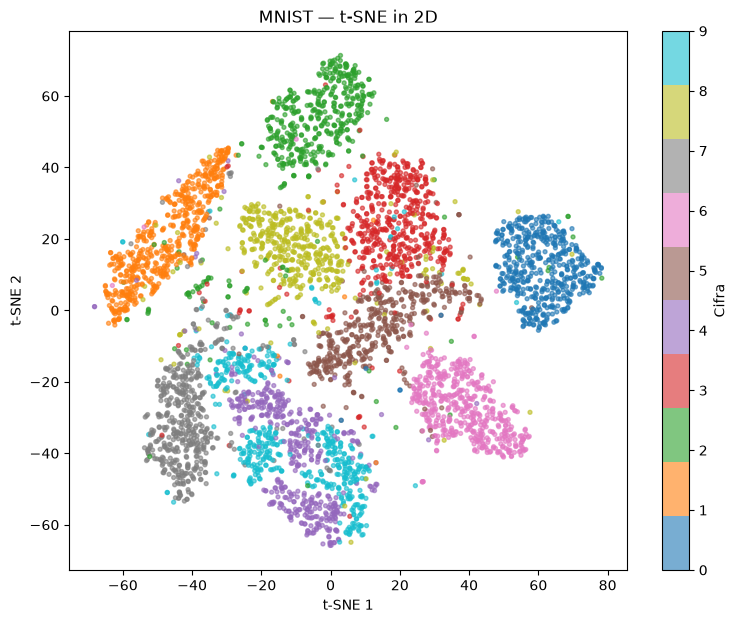

In [19]:
from sklearn.manifold import TSNE

X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    max_iter=1000
).fit_transform(X_sub)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_sub, cmap="tab10", s=8, alpha=0.6
)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("MNIST — t-SNE in 2D")
plt.colorbar(scatter, ticks=range(10), label="Cifra")
plt.show()

---

## More resources
* [video explaining PCA vs t-SNE vs UMAP](https://youtu.be/o_cAOa5fMhE?si=9vvkppYAbKtFpLRn) 
*   [Effect of Rescaling in PCA](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)
*   [PCA math](https://youtu.be/dhK8nbtii6I?si=8PCuyZn0kT-BLuW3)
*   [t-SNE](https://youtu.be/NEaUSP4YerM?si=HZx3uzCCxG8oNQzC)
*   [Eigenvectors and Eigenvalues](https://youtu.be/PFDu9oVAE-g?si=Ubv-fdszu1_Lqyjp)